# STS-B Sentence Similarity: Transformer Assignment
Task: predict how similar two sentences are (score 0 to 5).
Dataset: GLUE / STS-B | Models: bert-base-uncased, sentence-transformers/all-MiniLM-L6-v2
Metrics: Accuracy, Precision, Recall, F1 (plus Pearson/Spearman for regression)

Roadmap: 1 Setup, 2 Metrics, 3 Data, 4 Tokenization, 5 Model, 6 Fine-tuning, 7 Evaluation, 8 Second model, 9 Custom examples, 10 Error analysis

## Module 1: Setup
**Goal:** get Colab ready with a GPU and the Hugging Face libraries.

**What we do:** switch runtime to T4 GPU, install transformers and datasets, import them, check versions, confirm the GPU is visible.

**Why:** every later step depends on this working.

In [ ]:
# Install the Hugging Face libraries (the '!' runs a shell command in Colab)
# transformers = models + tokenizers, datasets = dataset loading, accelerate = training helper
!pip install transformers datasets accelerate

In [ ]:
# numpy for arrays/maths, pandas for tables, matplotlib for plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# torch is the deep-learning framework the models run on
import torch
import transformers
import datasets
# Pearson/Spearman correlation: the regression metrics used in Module 7
from scipy.stats import pearsonr,spearmanr

In [ ]:
# GPU check: True means a GPU is available (this line only shows if it is the last expression)
torch.cuda.is_available()
# Print library versions so the run is reproducible
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("numpy",np.__version__)

torch: 2.11.0+cu130
transformers: 5.22.0
datasets: 4.8.5
numpy 2.4.6


## Module 2: Metrics from Scratch
**Goal:** build confusion-matrix metrics in numpy, no sklearn at first.

**What we do:** count TP, FP, FN, TN, then compute accuracy, precision, recall, F1.

**Why:** the assignment needs these four metrics; building them by hand shows what they mean. Later we check against sklearn.

In [ ]:
# 2a: confusion-matrix metrics with a plain loop
# y_true = real labels, y_pred = model guesses (1 = similar, 0 = not similar)
y_true = [1, 0, 1, 1, 0, 1, 0, 0]
y_pred = [1, 0, 0, 1, 0, 1, 1, 0]

# convert the lists to numpy arrays
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
#i changes them to np arrya
# tp/tn/fp/fn = true positives, true negatives, false positives, false negatives
tp,tn,fp,fn =0,0,0,0
for i in range(len(y_true)):
  # right answer = 1 and predicted 1 -> true positive
  if (y_true[i] == 1 and y_pred[i]==1):
    tp+=1
  # right answer = 0 and predicted 0 -> true negative
  elif (y_true[i] == 0 and y_pred[i]==0):
    tn+=1
  # right answer = 0 but predicted 1 -> false positive
  elif (y_true[i] == 0 and y_pred[i]==1):
    fp+=1
  # right answer = 1 but predicted 0 -> false negative
  elif (y_true[i] == 1 and y_pred[i]==0):
    fn+=1

# accuracy = share of all predictions that were right
accuracy = (tp+tn)/(tp+tn+fp+fn)
# precision = of everything predicted 'similar', how much really was
precision = tp/(tp+fp)
# recall = of everything really 'similar', how much we found
recall =tp /(tp+fn)
# F1 = balance of precision and recall
f1 = 2*precision*recall /(precision+recall)
print(f"accuracy ={accuracy} precision ={precision} recall ={recall} f1 ={f1}")

accuracy =0.75 precision =0.75 recall =0.75 f1 =0.75


In [ ]:
# 2b: the same counts with numpy boolean masks (no loop)
y_true = [1, 0, 1, 1, 0, 1, 0, 0]
y_pred = [1, 0, 0, 1, 0, 1, 1, 0]

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)

# (a == 1) & (b == 1) gives True/False per position; np.sum counts the Trues
tp = np.sum((y_true==1) & (y_pred==1))
tn = np.sum((y_true==0) & (y_pred==0))
fp = np.sum((y_true==0) & (y_pred==1))
fn = np.sum((y_true==1) & (y_pred==0))

# note the brackets: (tp+tn)/(...) so the division happens after the addition
accuracy = (tp+tn)/(tp+tn+fp+fn)
# guard: if the denominator is 0, return 0 instead of dividing by zero
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
# NOTE: f1 has no zero-division guard here (it is added in cell 2c)
f1 = 2*precision*recall /(precision+recall)
print(f"accuracy ={accuracy} precision ={precision} recall ={recall} f1 ={f1}")

accuracy =0.75 precision =0.75 recall =0.75 f1 =0.75


In [ ]:
# 2c: reusable function that RETURNS the four metrics as a dictionary
def compute_metrics(y_true,y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # confusion-matrix counts (numpy masks, as in 2b)
    tp = np.sum((y_true==1) & (y_pred==1))
    tn = np.sum((y_true==0) & (y_pred==0))
    fp = np.sum((y_true==0) & (y_pred==1))
    fn = np.sum((y_true==1) & (y_pred==0))

    accuracy = (tp+tn)/(tp+tn+fp+fn)
    # every division is guarded so an all-zero prediction does not crash
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2*precision*recall /(precision+recall) if (precision+recall)>0 else 0
    # dictionary values go in bare (no extra braces)
    # NOTE: the key "recall " has a trailing space, so result["recall"] would fail
    return {"accuracy": accuracy ,"precision": precision ,"recall ":recall ,"f1" :f1}


# normal case, expected 0.75 for all four
compute_metrics([1, 0, 1, 1, 0, 1, 0, 0],[1, 0, 0, 1, 0, 1, 1, 0])
# edge case: the model predicts 'not similar' for everything (accuracy 0.5, the rest 0)
compute_metrics([1,0,1,1,0,1,0,0], [0]*8)

{'accuracy': np.float64(0.5),
 'precision': 0,
 'recall ': np.float64(0.0),
 'f1': 0}

In [ ]:
# 2d: cross-check against sklearn's ready-made metrics
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
y_true = [1, 0, 1, 1, 0, 1, 0, 0]
y_pred = [1, 0, 0, 1, 0, 1, 1, 0]

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
# NOTE: this REDEFINES compute_metrics (same name as cell 2c), so it overwrites the
# numpy version above. This one uses sklearn and prints instead of returning.
def compute_metrics(y_true,y_pred):
    accuracy= accuracy_score(y_true,y_pred)
    # sklearn warns when there are no predicted positives; zero_division=0 would silence it
    precision = precision_score(y_true,y_pred)
    recall = recall_score(y_true,y_pred)
    f1 = f1_score(y_true,y_pred)
    print(f"accuracy ={accuracy} precision ={precision} recall ={recall} f1 ={f1}")


compute_metrics([1, 0, 1, 1, 0, 1, 0, 0],[1, 0, 0, 1, 0, 1, 1, 0])
compute_metrics([1,0,1,1,0,1,0,0], [0]*8)

accuracy =0.75 precision =0.75 recall =0.75 f1 =0.75
accuracy =0.5 precision =0.0 recall =0.0 f1 =0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Module 3: The STS-B Dataset
**Goal:** load and understand the data.

**What we do:** load glue/stsb, look at train/validation/test splits, print example pairs, plot the score distribution.

**Why:** you can't fine-tune well on data you haven't looked at.

In [30]:
# TODO 3a: load dataset
# load_dataset needs the full 'owner/name' on newer versions: "nyu-mll/glue", task "stsb"
from datasets import load_dataset
ds = load_dataset("nyu-mll/glue","stsb")
# ds alone is not the last line, so it will not display; the prints below do
ds
# first 3 rows of each split (test labels are -1 because GLUE hides them)
print(ds["train"][:3])
print(ds["validation"][:3])
print(ds["test"][:3])

{'sentence1': ['A plane is taking off.', 'A man is playing a large flute.', 'A man is spreading shreded cheese on a pizza.'], 'sentence2': ['An air plane is taking off.', 'A man is playing a flute.', 'A man is spreading shredded cheese on an uncooked pizza.'], 'label': [5.0, 3.799999952316284, 3.799999952316284], 'idx': [0, 1, 2]}
{'sentence1': ['A man with a hard hat is dancing.', 'A young child is riding a horse.', 'A man is feeding a mouse to a snake.'], 'sentence2': ['A man wearing a hard hat is dancing.', 'A child is riding a horse.', 'The man is feeding a mouse to the snake.'], 'label': [5.0, 4.75, 5.0], 'idx': [0, 1, 2]}
{'sentence1': ['A girl is styling her hair.', 'A group of men play soccer on the beach.', "One woman is measuring another woman's ankle."], 'sentence2': ['A girl is brushing her hair.', 'A group of boys are playing soccer on the beach.', "A woman measures another woman's ankle."], 'label': [-1.0, -1.0, -1.0], 'idx': [0, 1, 2]}


4
min in training label,0.0
max in training label,5.0
min in test label,-1.0
max in test label,-1.0
min in validation label,0.0
max in validation label,5.0
['sentence1', 'sentence2', 'label', 'idx']
0.0
5.0
5749
mean of train,2.7009990240624933


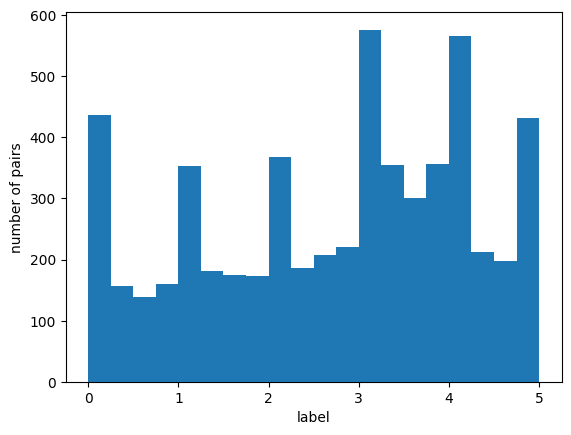

count higher that label 3: 2994


In [40]:
# 3b/3c: explore the dataset
# number of columns: sentence1, sentence2, label, idx
print(len(ds["train"].column_names))

# label range in each split (test is all -1 = hidden labels)
print(f"min in training label,{min(ds["train"]["label"])}")
print(f"max in training label,{max(ds["train"]["label"])}")
print(f"min in test label,{min(ds["test"]["label"])}")
print(f"max in test label,{max(ds["test"]["label"])}")
print(f"min in validation label,{min(ds["validation"]["label"])}")
print(f"max in validation label,{max(ds["validation"]["label"])}")

# (these four lines repeat the train checks above)
print(ds["train"].column_names)
print(min(ds["train"]["label"]))
print(max(ds["train"]["label"]))
# number of training pairs
print(len(ds["train"]))
labels = np.asarray(ds["train"]["label"])
print(f"mean of train,{np.mean(ds["train"]["label"])}")
# histogram of the similarity scores (0 to 5) in 20 bars
plt.hist(labels,bins=20)
plt.xlabel("label")
plt.ylabel("number of pairs")
plt.show()

# how many pairs score 3.0 or higher (candidate 'similar' class for Module 7)
totalthree = np.asarray(labels)>=3.0
total_count = np.sum(totalthree)
count =0
for i in ds["train"]["label"]:
  if i >=3.0:
    count+=1
print(f"count higher that label 3: {count}")

## Module 4: Tokenization
**Goal:** turn sentence pairs into numbers the model can read.

**What we do:** load the BERT tokenizer, tokenize a pair, inspect input_ids, token_type_ids, attention_mask, then tokenize the whole dataset.

**Why:** models only understand numbers, not text.

In [ ]:
# TODO 4a: tokenize one pair and inspect

In [ ]:
# TODO 4b: tokenize the full dataset

## Module 5: Loading the Model
**Goal:** load BERT with a regression head and run one forward pass.

**What we do:** load bert-base-uncased with one output (num_labels=1), feed in one batch, look at the output shape.

**Why:** this is the wx+b idea on top of a pretrained model.

In [ ]:
# TODO 5a: load model

In [ ]:
# TODO 5b: one forward pass

## Module 6: Fine-tuning
**Goal:** train the model on STS-B.

**What we do:** set the loss (MSE), optimizer and learning rate, run the training loop (or Trainer), watch the loss go down.

**Why:** this is gradient descent on a real model.

In [ ]:
# TODO 6a: training setup

In [ ]:
# TODO 6b: train

## Module 7: Evaluation
**Goal:** measure performance two ways.

**What we do:** (1) Pearson and Spearman correlation on raw scores. (2) Pick a threshold (e.g. 3.0) to turn scores into similar / not similar, then compute Accuracy, Precision, Recall, F1 with the Module 2 functions.

**Why:** the assignment asks for classification metrics on a regression task.

In [ ]:
# TODO 7a: predictions on validation set

In [ ]:
# TODO 7b: correlation metrics

In [ ]:
# TODO 7c: threshold + classification metrics

## Module 8: Second Model and Comparison
**Goal:** repeat the pipeline with all-MiniLM-L6-v2 and compare.

**What we do:** reuse the earlier code, then build a results table for both models.

**Why:** the assignment requires a comparison.

In [ ]:
# TODO 8a: fine-tune MiniLM

In [ ]:
# TODO 8b: comparison table

## Module 9: Custom Examples
**Goal:** test the models on 5 or more sentence pairs of our own.

**What we do:** write pairs (very similar, unrelated, tricky), predict scores, compare the two models.

**Why:** the assignment requires at least 5 custom predictions.

In [ ]:
# TODO 9: custom predictions

## Module 10: Error Analysis and Conclusion
**Goal:** understand where and why the models fail.

**What we do:** find the biggest errors, look for patterns (negation, word overlap, length), write the conclusion.

**Why:** the assignment requires error analysis.

In [ ]:
# TODO 10a: biggest errors